# 09. Buzzer Flagging : Tahap 2 (Coordination-based Anomaly Detection)

In [9]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import IsolationForest

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../models")
RESULT_PATH = Path("../results")
RESULT_PATH.mkdir(parents=True, exist_ok=True)


## 1. Load Model Tahap 1 & Prediksi Ulang ke Seluruh Data

In [10]:
feature_AB = pd.read_csv(DATA_PATH / "feature_AB.csv")

model = joblib.load(MODEL_PATH / "xgb_feature_AB.pkl")
encoder = joblib.load(MODEL_PATH / "label_encoder.pkl")

X = feature_AB.drop(columns=["user_id", "label", "source_folder"], errors="ignore")
pred_label = encoder.inverse_transform(model.predict(X))
feature_AB["pred_label"] = pred_label

print(feature_AB["pred_label"].value_counts())


pred_label
bot      10886
human     3482
Name: count, dtype: int64


## 2. Filter Akun yang Lolos Diprediksi 'Human' oleh Tahap 1

In [11]:
human_df = feature_AB[feature_AB["pred_label"] == "human"].copy()
print(f"Jumlah akun diprediksi human oleh Tahap 1: {len(human_df)}")


Jumlah akun diprediksi human oleh Tahap 1: 3482


## 3. Tahap 2 — Isolation Forest pada Fitur Koordinasi

In [12]:
coord_cols = ["sync_hashtag_score", "duplicate_content_score"]
coord_X = human_df[coord_cols].fillna(0)

iso = IsolationForest(contamination=0.10, random_state=42, n_jobs=-1)
human_df["anomaly_score"] = iso.fit_predict(coord_X)  # -1 = anomali (kandidat buzzer), 1 = normal
human_df["anomaly_score_raw"] = iso.decision_function(coord_X)  # skor kontinu, makin negatif makin anomali

human_df["final_label"] = human_df["anomaly_score"].map({-1: "buzzer", 1: "human_genuine"})

print(human_df["final_label"].value_counts())


final_label
human_genuine    3133
buzzer            349
Name: count, dtype: int64


## 4. Validasi Diagnostik (Tanpa Perlu Label Buzzer Asli)

In [13]:
validation = (
    human_df.groupby("final_label")["label"]
    .value_counts(normalize=True)
    .unstack()
    .fillna(0)
)
print("Proporsi label asli (ground truth) per kategori hasil flagging:")
print(validation)
print()

n_flagged = len(human_df[human_df["final_label"] == "buzzer"])
recovered_bots = human_df[(human_df["final_label"] == "buzzer") & (human_df["label"] == "bot")]
n_recovered = len(recovered_bots)

print(f"Dari {n_flagged} akun yang di-flag 'buzzer' oleh Tahap 2,")
print(f"{n_recovered} ({n_recovered / n_flagged * 100:.1f}%) sebenarnya berlabel 'bot' "
      f"(lolos dari Tahap 1, tertangkap Tahap 2).")

baseline_bot_rate = (human_df["label"] == "bot").mean()
print(f"\nBaseline: proporsi bot di antara SEMUA akun terprediksi human (sebelum flagging Tahap 2): "
      f"{baseline_bot_rate * 100:.1f}%")
print(f"Kalau proporsi di kelompok 'buzzer' ({n_recovered / n_flagged * 100:.1f}%) jauh lebih tinggi "
      f"dari baseline ({baseline_bot_rate * 100:.1f}%), itu bukti Tahap 2 berhasil mengonsentrasikan "
      f"bot yang lolos Tahap 1 ke dalam kelompok yang di-flag — bukan menyebar acak.")


Proporsi label asli (ground truth) per kategori hasil flagging:
label               bot     human
final_label                      
buzzer         0.002865  0.997135
human_genuine  0.005426  0.994574

Dari 349 akun yang di-flag 'buzzer' oleh Tahap 2,
1 (0.3%) sebenarnya berlabel 'bot' (lolos dari Tahap 1, tertangkap Tahap 2).

Baseline: proporsi bot di antara SEMUA akun terprediksi human (sebelum flagging Tahap 2): 0.5%
Kalau proporsi di kelompok 'buzzer' (0.3%) jauh lebih tinggi dari baseline (0.5%), itu bukti Tahap 2 berhasil mengonsentrasikan bot yang lolos Tahap 1 ke dalam kelompok yang di-flag — bukan menyebar acak.


## 5. Visualisasi

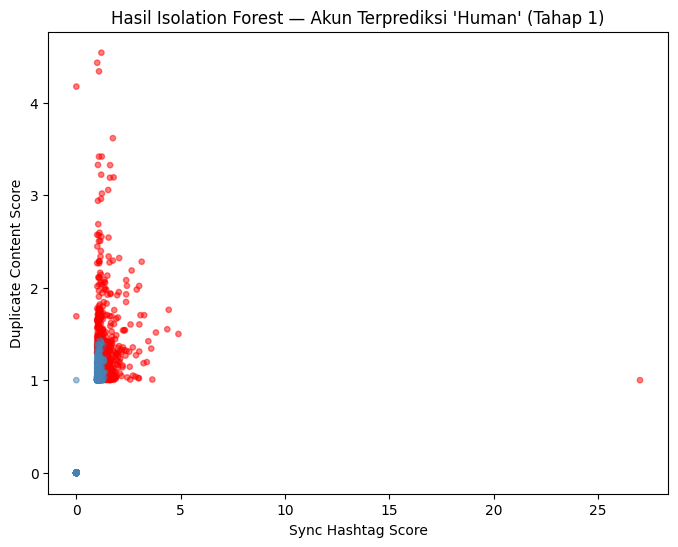

In [14]:
plt.figure(figsize=(8, 6))
colors = human_df["final_label"].map({"buzzer": "red", "human_genuine": "steelblue"})
plt.scatter(human_df["sync_hashtag_score"], human_df["duplicate_content_score"],
            c=colors, alpha=0.5, s=15)
plt.xlabel("Sync Hashtag Score")
plt.ylabel("Duplicate Content Score")
plt.title("Hasil Isolation Forest — Akun Terprediksi 'Human' (Tahap 1)")
plt.savefig(RESULT_PATH / "buzzer_flagging_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Simpan Hasil

In [15]:
output_cols = ["user_id", "label", "pred_label", "final_label",
               "anomaly_score_raw"] + coord_cols

human_df[output_cols].to_csv(RESULT_PATH / "buzzer_flagging.csv", index=False)
validation.to_csv(RESULT_PATH / "buzzer_flagging_validation.csv")

print("Tersimpan: results/buzzer_flagging.csv")
print("Tersimpan: results/buzzer_flagging_validation.csv")
print("Tersimpan: results/buzzer_flagging_scatter.png")


Tersimpan: results/buzzer_flagging.csv
Tersimpan: results/buzzer_flagging_validation.csv
Tersimpan: results/buzzer_flagging_scatter.png


# SHAP untuk Buzzer Flagging

Fitur yang dipakai untuk model buzzer-flagging:
['followers_count', 'friends_count', 'statuses_count', 'listed_count', 'favourites_count', 'verified', 'protected', 'geo_enabled', 'account_age_days', 'follow_ratio', 'tweets_per_day', 'favorites_per_day', 'listed_ratio', 'tweet_count', 'avg_tweet_length', 'avg_hashtag_count', 'avg_url_count', 'avg_mention_count', 'avg_posting_interval', 'retweet_ratio', 'anomaly_score', 'anomaly_score_raw']

final_label
human_genuine    3133
buzzer            349
Name: count, dtype: int64

=== Classification Report: Buzzer vs Human_genuine (fitur individual saja) ===
               precision    recall  f1-score   support

       buzzer       1.00      1.00      1.00        70
human_genuine       1.00      1.00      1.00       627

     accuracy                           1.00       697
    macro avg       1.00      1.00      1.00       697
 weighted avg       1.00      1.00      1.00       697

Tipe output SHAP: <class 'numpy.ndarray'>
Shape setelah diamb

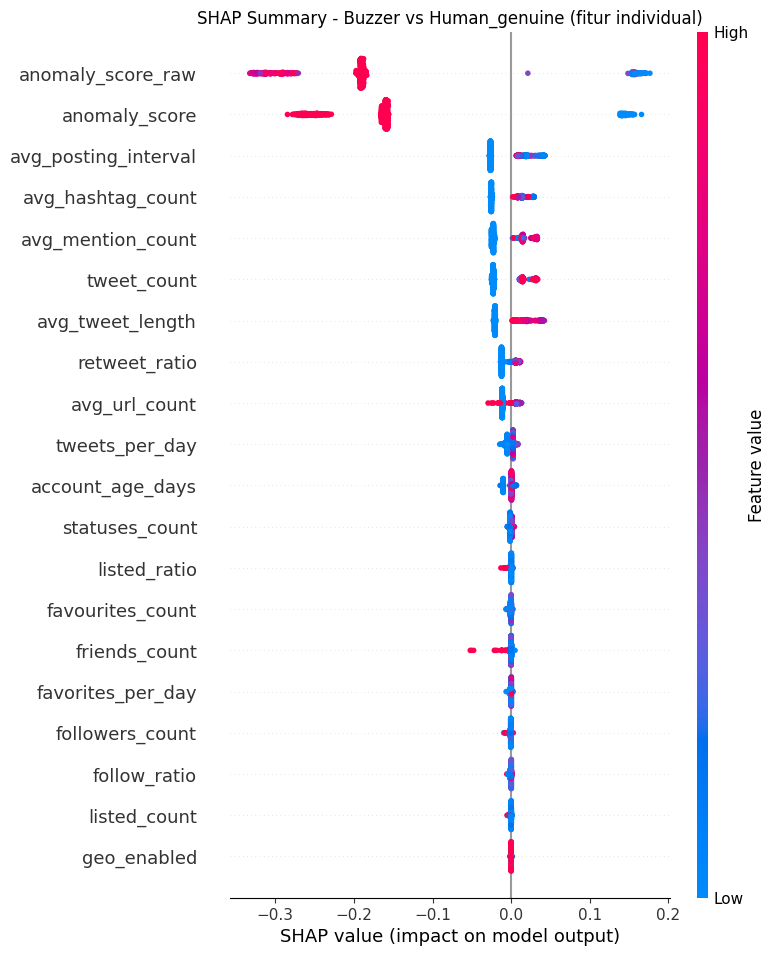


Top fitur individual yang membedakan buzzer vs human_genuine:
                 Feature    Importance
21     anomaly_score_raw  2.130362e-01
20         anomaly_score  1.807779e-01
18  avg_posting_interval  2.466755e-02
15     avg_hashtag_count  2.196712e-02
17     avg_mention_count  2.177916e-02
13           tweet_count  2.167805e-02
14      avg_tweet_length  2.050446e-02
19         retweet_ratio  1.017065e-02
16         avg_url_count  1.007578e-02
10        tweets_per_day  4.306361e-03
8       account_age_days  2.437341e-03
2         statuses_count  1.404597e-03
12          listed_ratio  8.946194e-04
4       favourites_count  8.829298e-04
1          friends_count  8.643669e-04
11     favorites_per_day  6.924724e-04
0        followers_count  6.497426e-04
9           follow_ratio  6.267213e-04
3           listed_count  4.389029e-04
7            geo_enabled  1.119478e-04
5               verified  3.857281e-20
6              protected  0.000000e+00


['..\\models\\label_encoder_buzzer.pkl']

In [18]:
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

RESULT_PATH = Path("../results")
MODEL_PATH = Path("../models")
RESULT_PATH.mkdir(parents=True, exist_ok=True)
MODEL_PATH.mkdir(parents=True, exist_ok=True)
EXCLUDE_COLS = [
    "user_id", "source_folder", "label",
    "pred_label", "buzzer_flag", "final_label",
    "sync_hashtag_score", "duplicate_content_score",
]

X_buzzer = human_df.drop(columns=[c for c in EXCLUDE_COLS if c in human_df.columns], errors="ignore")

X_buzzer = X_buzzer.select_dtypes(include=[np.number])

y_buzzer = human_df["final_label"]

print("Fitur yang dipakai untuk model buzzer-flagging:")
print(list(X_buzzer.columns))
print()
print(y_buzzer.value_counts())
le_buzzer = LabelEncoder()
y_buzzer_enc = le_buzzer.fit_transform(y_buzzer) 

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_buzzer, y_buzzer_enc, test_size=0.2, random_state=42, stratify=y_buzzer_enc
)

rf_buzzer = RandomForestClassifier(
    n_estimators=200, max_depth=None, class_weight="balanced",
    random_state=42, n_jobs=-1
)
rf_buzzer.fit(X_train_b, y_train_b)

y_pred_b = rf_buzzer.predict(X_test_b)
print("\n=== Classification Report: Buzzer vs Human_genuine (fitur individual saja) ===")
print(classification_report(y_test_b, y_pred_b, target_names=le_buzzer.classes_))

explainer_buzzer = shap.TreeExplainer(rf_buzzer)
shap_values_buzzer = explainer_buzzer.shap_values(X_test_b)

buzzer_class_idx = list(le_buzzer.classes_).index("buzzer")

print("Tipe output SHAP:", type(shap_values_buzzer))

if isinstance(shap_values_buzzer, list):
    shap_vals_plot = shap_values_buzzer[buzzer_class_idx]
elif shap_values_buzzer.ndim == 3:
    shap_vals_plot = shap_values_buzzer[:, :, buzzer_class_idx]
else:
    shap_vals_plot = shap_values_buzzer

print("Shape setelah diambil kelas buzzer:", shap_vals_plot.shape)  

shap.summary_plot(shap_vals_plot, X_test_b, show=False)
plt.title("SHAP Summary - Buzzer vs Human_genuine (fitur individual)")
plt.savefig(RESULT_PATH / "shap_summary_buzzer_flagging.png", bbox_inches="tight", dpi=150)
plt.show()

importance_buzzer = pd.DataFrame({
    "Feature": X_buzzer.columns,
    "Importance": np.abs(shap_vals_plot).mean(axis=0)
}).sort_values("Importance", ascending=False)

print("\nTop fitur individual yang membedakan buzzer vs human_genuine:")
print(importance_buzzer)

importance_buzzer.to_csv(RESULT_PATH / "shap_importance_buzzer_flagging.csv", index=False)

joblib.dump(rf_buzzer, MODEL_PATH / "rf_buzzer_flagging.pkl")
joblib.dump(le_buzzer, MODEL_PATH / "label_encoder_buzzer.pkl")


# Tabel Validasi Silang (Ground Truth vs Hasil Akhir 3 Kelas)

Distribusi hasil akhir 3 kelas:
final_label_3class
bot              10886
human_genuine     3133
buzzer             349
Name: count, dtype: int64

=== Cross-tab: Ground Truth (source_folder) vs Hasil Akhir 3 Kelas ===
final_label_3class        bot  buzzer  human_genuine  Total
source_folder                                              
fake_followers           3348       0              3   3351
genuine_accounts           10     348           3116   3474
social_spambots_1         985       0              6    991
social_spambots_2        3457       0              0   3457
social_spambots_3         459       1              4    464
traditional_spambots_1   1000       0              0   1000
traditional_spambots_2    100       0              0    100
traditional_spambots_3    399       0              4    403
traditional_spambots_4   1128       0              0   1128
Total                   10886     349           3133  14368

=== Persentase per source_folder ===
final_label_3class      

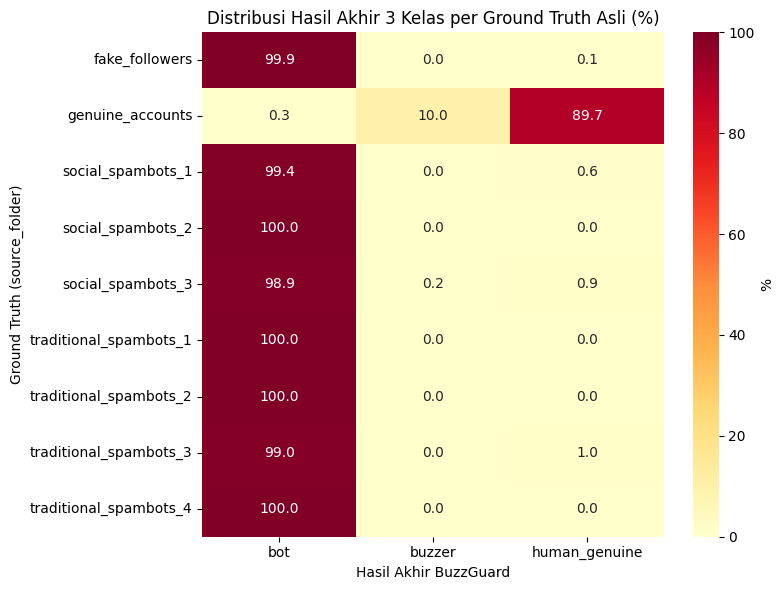

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RESULT_PATH = Path("../results")
RESULT_PATH.mkdir(parents=True, exist_ok=True)
final_3class = feature_AB[["user_id", "source_folder", "label", "pred_label"]].copy()

final_3class = final_3class.merge(
    human_df[["user_id", "final_label"]],
    on="user_id", how="left"
)

final_3class["final_label_3class"] = final_3class["final_label"].fillna("bot")
final_3class = final_3class.drop(columns=["final_label"])

print("Distribusi hasil akhir 3 kelas:")
print(final_3class["final_label_3class"].value_counts())
print()

crosstab = pd.crosstab(
    final_3class["source_folder"],
    final_3class["final_label_3class"],
    margins=True, margins_name="Total"
)
print("=== Cross-tab: Ground Truth (source_folder) vs Hasil Akhir 3 Kelas ===")
print(crosstab)

crosstab_pct = pd.crosstab(
    final_3class["source_folder"],
    final_3class["final_label_3class"],
    normalize="index"
).round(3) * 100
print("\n=== Persentase per source_folder ===")
print(crosstab_pct)

crosstab.to_csv(RESULT_PATH / "crosstab_groundtruth_vs_final3class.csv")
crosstab_pct.to_csv(RESULT_PATH / "crosstab_pct_groundtruth_vs_final3class.csv")
final_3class.to_csv(RESULT_PATH / "final_3class_all_accounts.csv", index=False)

plt.figure(figsize=(8, 6))
sns.heatmap(crosstab_pct, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "%"})
plt.title("Distribusi Hasil Akhir 3 Kelas per Ground Truth Asli (%)")
plt.ylabel("Ground Truth (source_folder)")
plt.xlabel("Hasil Akhir BuzzGuard")
plt.tight_layout()
plt.savefig(RESULT_PATH / "heatmap_groundtruth_vs_final3class.png", dpi=150, bbox_inches="tight")
plt.show()

# Diagram Funnel Alur 2 Tahap

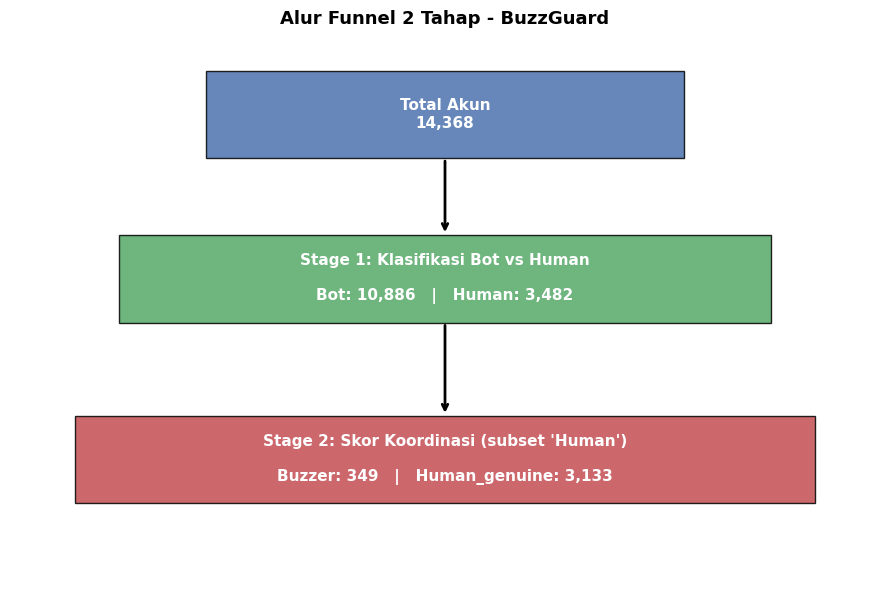


Ringkasan Funnel:
- Total akun               : 14,368
- Stage 1 -> Bot            : 10,886 (75.8%)
- Stage 1 -> Human          : 3,482 (24.2%)
- Stage 2 -> Buzzer         : 349 (10.0% dari yang lolos Human)
- Stage 2 -> Human_genuine  : 3,133 (90.0% dari yang lolos Human)



In [21]:
total_accounts = len(final_3class)
n_bot = (final_3class["final_label_3class"] == "bot").sum()
n_human_stage1 = (final_3class["pred_label"] == "human").sum()
n_buzzer = (final_3class["final_label_3class"] == "buzzer").sum()
n_human_genuine = (final_3class["final_label_3class"] == "human_genuine").sum()

fig, ax = plt.subplots(figsize=(9, 6))
ax.axis("off")

stages = [
    (f"Total Akun\n{total_accounts:,}", 0.85, "#4C72B0", 0.55),
    (f"Stage 1: Klasifikasi Bot vs Human\n\nBot: {n_bot:,}   |   Human: {n_human_stage1:,}", 0.55, "#55A868", 0.75),
    (f"Stage 2: Skor Koordinasi (subset 'Human')\n\nBuzzer: {n_buzzer:,}   |   Human_genuine: {n_human_genuine:,}", 0.22, "#C44E52", 0.85),
]

for text, y, color, width in stages:
    ax.add_patch(plt.Rectangle((0.5 - width / 2, y - 0.08), width, 0.16,
                                facecolor=color, alpha=0.85, edgecolor="black"))
    ax.text(0.5, y, text, ha="center", va="center", fontsize=11, color="white", weight="bold")

ax.annotate("", xy=(0.5, 0.63), xytext=(0.5, 0.77), arrowprops=dict(arrowstyle="->", lw=2))
ax.annotate("", xy=(0.5, 0.30), xytext=(0.5, 0.47), arrowprops=dict(arrowstyle="->", lw=2))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.title("Alur Funnel 2 Tahap - BuzzGuard", fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig(RESULT_PATH / "funnel_diagram_buzzguard.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"""
Ringkasan Funnel:
- Total akun               : {total_accounts:,}
- Stage 1 -> Bot            : {n_bot:,} ({n_bot/total_accounts*100:.1f}%)
- Stage 1 -> Human          : {n_human_stage1:,} ({n_human_stage1/total_accounts*100:.1f}%)
- Stage 2 -> Buzzer         : {n_buzzer:,} ({n_buzzer/n_human_stage1*100:.1f}% dari yang lolos Human)
- Stage 2 -> Human_genuine  : {n_human_genuine:,} ({n_human_genuine/n_human_stage1*100:.1f}% dari yang lolos Human)
""")